Dataset Loaded Successfully!
Dataset Shape: (61065, 17)

Available Columns:
['Unnamed: 0', 'Method', 'User-Agent', 'Pragma', 'Cache-Control', 'Accept', 'Accept-encoding', 'Accept-charset', 'language', 'host', 'cookie', 'content-type', 'connection', 'lenght', 'content', 'classification', 'URL']

Original Label Distribution:
classification
0    36000
1    25065
Name: count, dtype: int64

Class Distribution:
target
Normal       36000
Anomalous    25065
Name: count, dtype: int64

Model Training Completed!

Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      7200
   Anomalous       1.00      1.00      1.00      5013

    accuracy                           1.00     12213
   macro avg       1.00      1.00      1.00     12213
weighted avg       1.00      1.00      1.00     12213



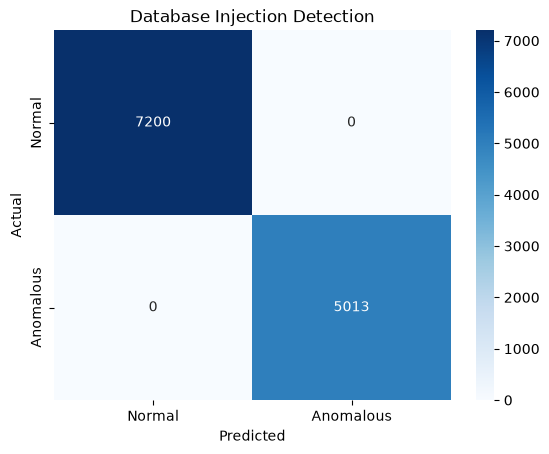


Sample Predictions:
      Actual  Predicted
0  Anomalous  Anomalous
1     Normal     Normal
2     Normal     Normal
3  Anomalous  Anomalous
4     Normal     Normal
5  Anomalous  Anomalous
6  Anomalous  Anomalous
7  Anomalous  Anomalous
8  Anomalous  Anomalous
9     Normal     Normal

Results saved successfully!


In [1]:
# Program 11: Database Injection Detection Using Decision Tree

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix

# Step 1: Load Dataset
df = pd.read_csv("csic_database.csv", low_memory=False)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# Step 2: Clean Column Names
df.columns = df.columns.str.strip()

print("\nAvailable Columns:")
print(df.columns.tolist())

# Step 3: Identify Label Column
possible_labels = ['label', 'class', 'classification', 'target']

label_column = next(
    (col for col in df.columns if col.lower() in possible_labels),
    None
)

if label_column is None:
    raise ValueError(
        "Label column not found. Please check the displayed column names."
    )

# Step 4: Remove Missing Labels
df = df.dropna(subset=[label_column]).copy()

# Step 5: Convert Labels
df[label_column] = (
    df[label_column].astype(str).str.strip().str.lower()
)

print("\nOriginal Label Distribution:")
print(df[label_column].value_counts())

# Map normal and attack labels
label_mapping = {
    'norm': 0,
    'normal': 0,
    'valid': 0,
    'benign': 0,
    '0': 0,
    'anom': 1,
    'anomalous': 1,
    'anomaly': 1,
    'attack': 1,
    'malicious': 1,
    '1': 1
}

df['target'] = df[label_column].map(label_mapping)

# Check label mapping
if df['target'].isna().any():
    unknown = df.loc[df['target'].isna(), label_column].unique()
    raise ValueError("Unknown label values found: " + str(unknown))

df['target'] = df['target'].astype(int)

# Step 6: Identify HTTP Request Features
excluded_columns = [
    label_column,
    'target',
    'index',
    'id'
]

text_columns = [
    col for col in df.columns
    if col.lower() not in excluded_columns
]

if not text_columns:
    raise ValueError("No HTTP request features found.")

# Step 7: Combine HTTP Request Data
X = df[text_columns].fillna('').astype(str).agg(' '.join, axis=1)

y = df['target']

print("\nClass Distribution:")
print(y.value_counts().rename({
    0: 'Normal',
    1: 'Anomalous'
}))

# Step 8: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 9: Create Decision Tree Model
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=20000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', DecisionTreeClassifier(
        max_depth=20,
        random_state=42,
        class_weight='balanced'
    ))
])

# Step 10: Train Model
model.fit(X_train, y_train)

print("\nModel Training Completed!")

# Step 11: Predict Results
y_pred = model.predict(X_test)

# Step 12: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:",
      round(accuracy * 100, 2), "%")

# Step 13: Classification Report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Normal', 'Anomalous'],
    zero_division=0
))

# Step 14: Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Anomalous'],
    yticklabels=['Normal', 'Anomalous']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Database Injection Detection")
plt.show()

# Step 15: Save Results
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results['Actual'] = results['Actual'].map({
    0: 'Normal',
    1: 'Anomalous'
})

results['Predicted'] = results['Predicted'].map({
    0: 'Normal',
    1: 'Anomalous'
})

results.to_csv("database_injection_results.csv", index=False)

print("\nSample Predictions:")
print(results.head(10))

print("\nResults saved successfully!")